# Exploratory Data Analysis: MNIST & CIFAR-10

A side-by-side EDA of two classic image-classification benchmarks.

| | MNIST | CIFAR-10 |
|---|---|---|
| Content | Handwritten digits | Everyday objects (animals, vehicles) |
| Image size | 28 x 28, grayscale | 32 x 32, RGB |
| Train / Test | 60,000 / 10,000 | 50,000 / 10,000 |
| Classes | 10 | 10 |

**Outline**

1. Setup & data loading
2. Structure & integrity checks
3. Class distribution
4. Visual inspection (sample grids)
5. Pixel-intensity statistics
6. Per-image statistics (brightness / contrast) & outliers
7. Class-average and class-variability images
8. Inter-class similarity
9. Duplicates & train/test leakage
10. Dimensionality reduction (PCA, t-SNE)
11. Dataset-specific analysis (MNIST: ink, bounding box, centre of mass: CIFAR-10: colour, edges)
12. Baseline separability (kNN / Logistic Regression on PCA features)
13. Summary

In [1]:
# Dependencies
%pip install -q numpy pandas matplotlib seaborn scipy scikit-learn torchvision

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Setup & data loading

In [2]:
import os, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import ndimage
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from torchvision import datasets
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
RNG = np.random.default_rng(SEED)
DATA_ROOT = "../../data/"

Both datasets are loaded with `torchvision` (downloaded automatically on first run, ~170 MB for CIFAR-10) and converted to NumPy arrays of shape `(N, H, W, C)` with dtype `uint8`.

In [3]:
CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
MNIST_CLASSES = [str(i) for i in range(10)]

def load_mnist():
    tr = datasets.MNIST(DATA_ROOT, train=True, download=True)
    te = datasets.MNIST(DATA_ROOT, train=False, download=True)
    return dict(Xtr=tr.data.numpy()[..., None], ytr=tr.targets.numpy(),
                Xte=te.data.numpy()[..., None], yte=te.targets.numpy(), classes=MNIST_CLASSES)

def load_cifar10():
    tr = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
    te = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
    return dict(Xtr=np.asarray(tr.data), ytr=np.asarray(tr.targets),
                Xte=np.asarray(te.data), yte=np.asarray(te.targets), classes=CIFAR_CLASSES)

DS = {"MNIST": load_mnist(), "CIFAR-10": load_cifar10()}

100.0%
100.0%
100.0%
100.0%
100.0%


In [4]:
# Small helpers reused throughout the notebook
def cmap_for(X):
    return "gray" if X.shape[-1] == 1 else None

def sample_idx(n, k):
    """Random subset of indices (no replacement), capped at n."""
    return RNG.choice(n, size=min(k, n), replace=False)

def flatten_float(X):
    return X.reshape(len(X), -1).astype(np.float32) / 255.0

def class_grid(d, n_per_class=8, title=""):
    """Grid with one row per class and n random training examples in each row."""
    X, y, classes = d["Xtr"], d["ytr"], d["classes"]
    fig, axes = plt.subplots(10, n_per_class, figsize=(n_per_class * 1.2 + 1, 12))
    for c in range(10):
        idx = RNG.choice(np.where(y == c)[0], n_per_class, replace=False)
        for j, i in enumerate(idx):
            ax = axes[c, j]
            ax.imshow(X[i].squeeze(), cmap=cmap_for(X))
            ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values(): s.set_visible(False)
        axes[c, 0].set_ylabel(classes[c], rotation=0, ha="right", va="center", fontsize=10)
    fig.suptitle(title, y=0.995, fontsize=13)
    plt.tight_layout()
    plt.show()

def show_images(X, titles, ncols=10, figsize_per=1.3, suptitle=""):
    n = len(X); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * figsize_per, nrows * (figsize_per + 0.35)), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for k in range(n):
        axes[k // ncols, k % ncols].imshow(X[k].squeeze(), cmap=cmap_for(X))
        axes[k // ncols, k % ncols].set_title(titles[k], fontsize=8)
    fig.suptitle(suptitle, fontsize=12)
    plt.tight_layout()
    plt.show()

## 2. Structure & integrity checks

Confirm shapes, dtypes, value ranges, label ranges and memory footprint. Because the data are `uint8` arrays, `NaN`/`inf` values are impossible by construction, we still check the pixel range and label validity.

In [5]:
rows = []
for name, d in DS.items():
    X = d["Xtr"]
    rows.append({
        "dataset": name,
        "train samples": len(d["Xtr"]),
        "test samples": len(d["Xte"]),
        "image shape (H,W,C)": X.shape[1:],
        "dtype": str(X.dtype),
        "pixel min": int(min(X.min(), d["Xte"].min())),
        "pixel max": int(max(X.max(), d["Xte"].max())),
        "n classes": len(np.unique(d["ytr"])),
        "labels valid (0-9)": bool(set(np.unique(d["ytr"])) | set(np.unique(d["yte"])) <= set(range(10))),
        "train memory (MB)": round(X.nbytes / 1e6, 1),
        "features / image": int(np.prod(X.shape[1:])),
    })
overview = pd.DataFrame(rows).set_index("dataset").T
overview

dataset,MNIST,CIFAR-10
train samples,60000,50000
test samples,10000,10000
"image shape (H,W,C)","(28, 28, 1)","(32, 32, 3)"
dtype,uint8,uint8
pixel min,0,0
pixel max,255,255
n classes,10,10
labels valid (0-9),True,True
train memory (MB),47.0,153.6
features / image,784,3072


## 3. Class distribution

Imbalanced classes would affect metric choice (accuracy vs. macro-F1) and loss weighting.

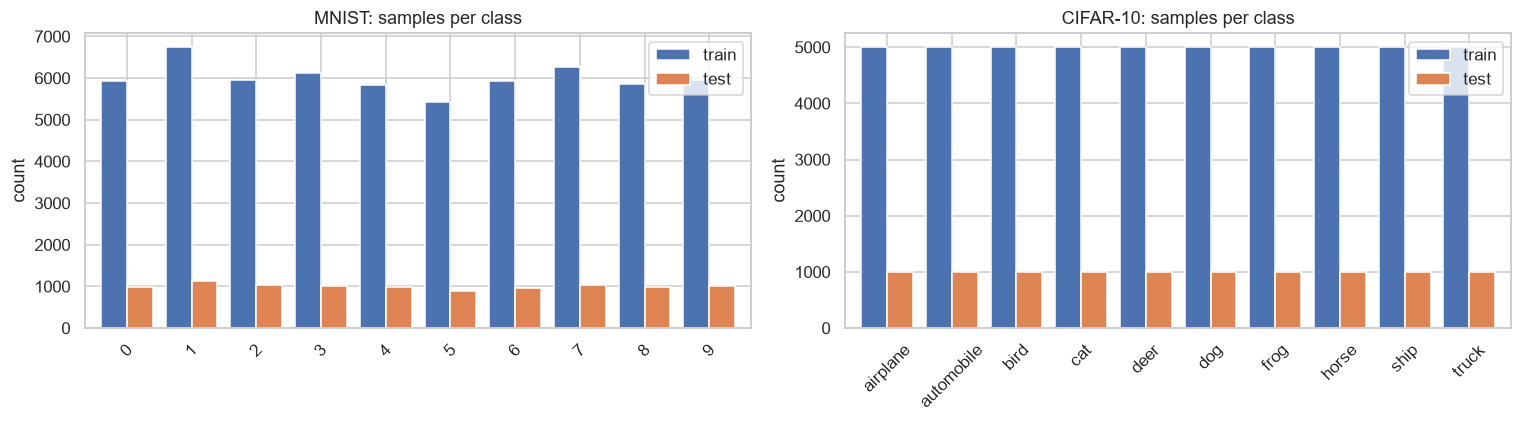

,train min,train max,imbalance ratio (max/min),train share range (%)
dataset,,,,
MNIST,5421,6742,1.244,9.04 - 11.24
CIFAR-10,5000,5000,1.000,10.00 - 10.00


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
balance_rows = []
for ax, (name, d) in zip(axes, DS.items()):
    tr = pd.Series(d["ytr"]).value_counts().sort_index()
    te = pd.Series(d["yte"]).value_counts().sort_index()
    df = pd.DataFrame({"train": tr.values, "test": te.values}, index=d["classes"])
    df.plot.bar(ax=ax, width=0.8)
    ax.set_title(f"{name}: samples per class")
    ax.set_ylabel("count")
    ax.tick_params(axis="x", rotation=45)
    balance_rows.append({"dataset": name,
                         "train min": tr.min(), "train max": tr.max(),
                         "imbalance ratio (max/min)": round(tr.max() / tr.min(), 3),
                         "train share range (%)": f"{100*tr.min()/tr.sum():.2f} - {100*tr.max()/tr.sum():.2f}"})
plt.tight_layout(); plt.show()
pd.DataFrame(balance_rows).set_index("dataset")

## 4. Visual inspection

One row per class, eight random training examples each. Look for label noise, intra-class variability, backgrounds, orientation and framing.

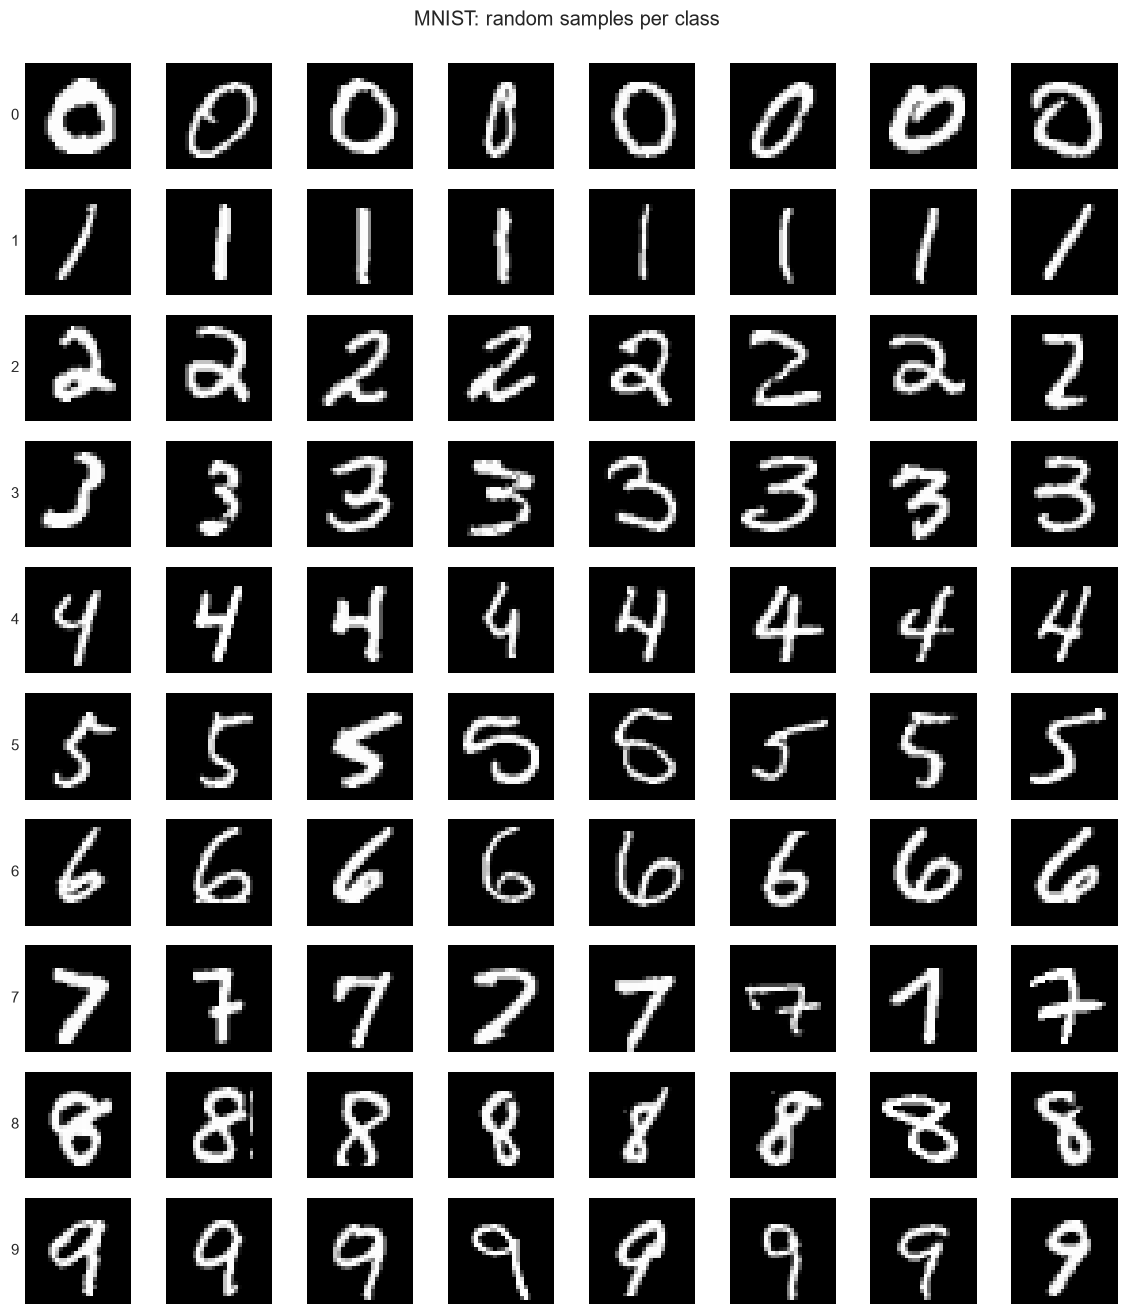

In [7]:
class_grid(DS["MNIST"], title="MNIST: random samples per class")

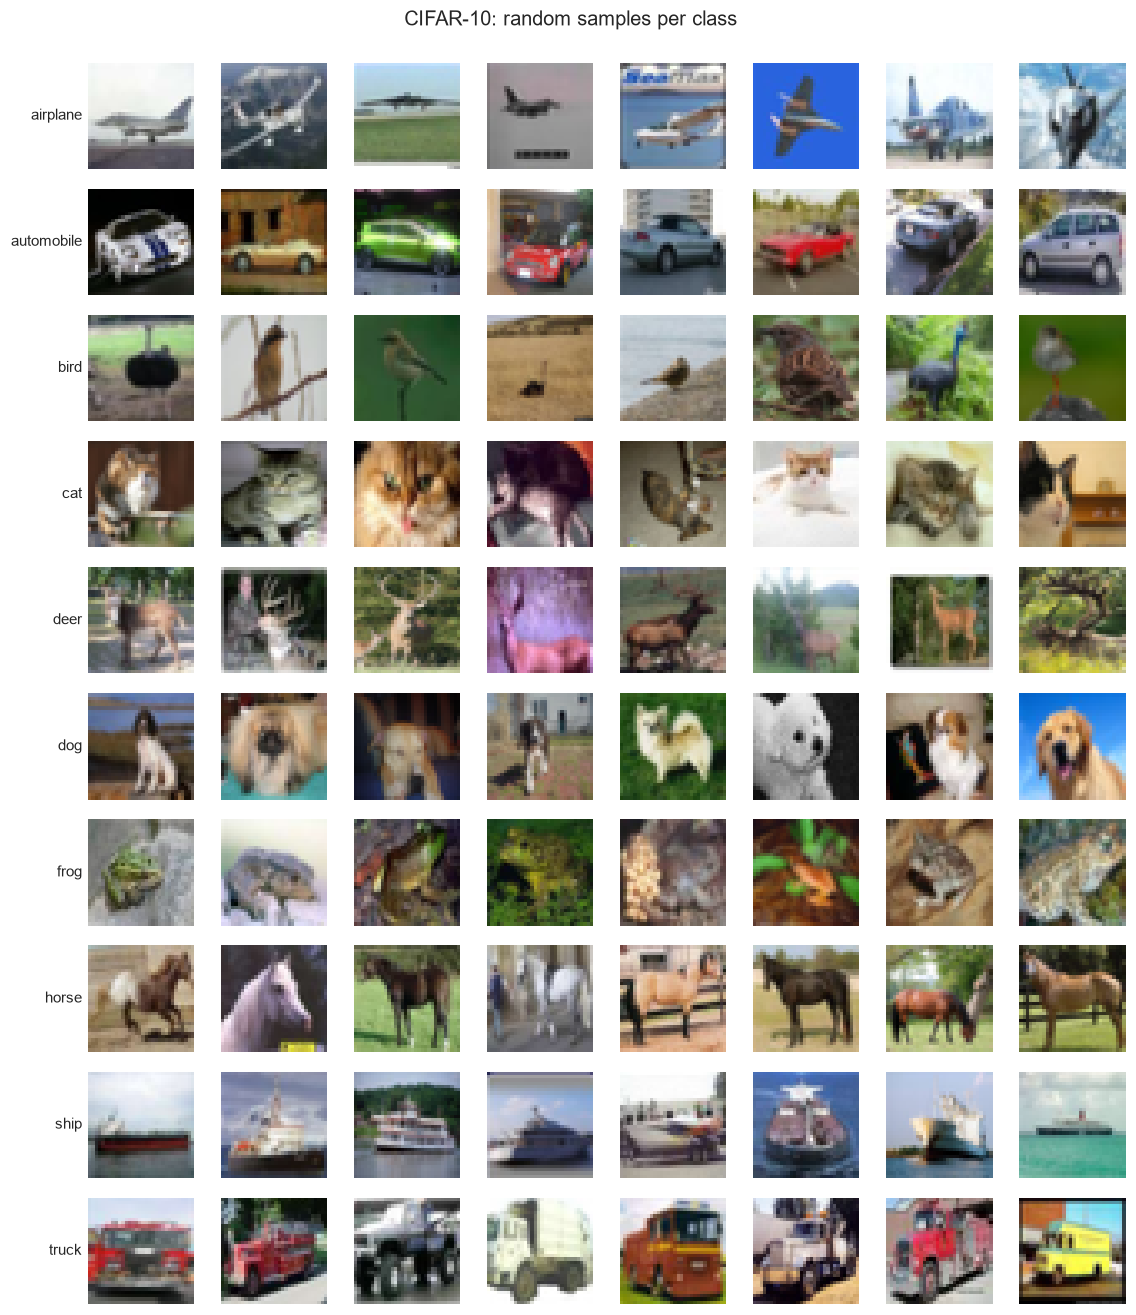

In [8]:
class_grid(DS["CIFAR-10"], title="CIFAR-10: random samples per class")

## 5. Pixel-intensity statistics

Global pixel distribution, and the per-channel mean / std that are typically used for input normalisation.

In [9]:
norm_rows = []
for name, d in DS.items():
    X = d["Xtr"]
    ch_mean = np.array([X[..., c].mean(dtype=np.float64) for c in range(X.shape[-1])]) / 255
    ch_std = np.array([X[..., c].std(dtype=np.float64) for c in range(X.shape[-1])]) / 255
    norm_rows.append({"dataset": name,
                      "channel mean": np.round(ch_mean, 4).tolist(),
                      "channel std": np.round(ch_std, 4).tolist(),
                      "fraction of zero pixels": round(float((X == 0).mean()), 4),
                      "fraction of 255 pixels": round(float((X == 255).mean()), 4)})
pd.DataFrame(norm_rows).set_index("dataset")

,channel mean,channel std,fraction of zero pixels,fraction of 255 pixels
dataset,,,,
MNIST,[0.1307],[0.3081],0.8088,0.0067
CIFAR-10,"[0.4914, 0.4822, 0.4465]","[0.247, 0.2435, 0.2616]",0.0024,0.0097


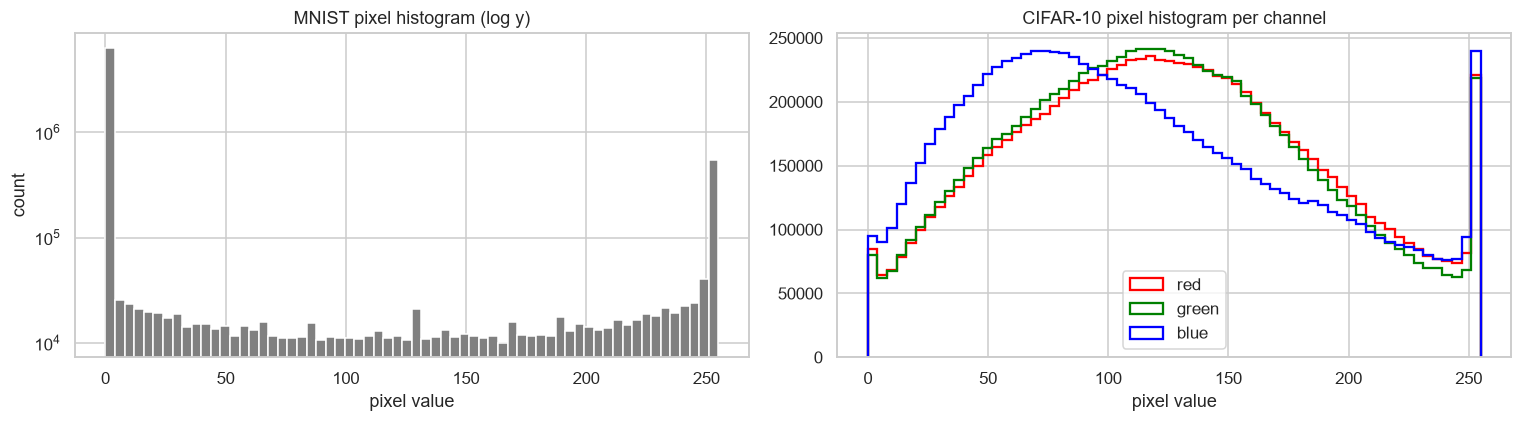

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# MNIST: highly bimodal -> log scale
X = DS["MNIST"]["Xtr"]; s = X[sample_idx(len(X), 10000)].ravel()
axes[0].hist(s, bins=64, color="gray"); axes[0].set_yscale("log")
axes[0].set_title("MNIST pixel histogram (log y)"); axes[0].set_xlabel("pixel value"); axes[0].set_ylabel("count")
# CIFAR: per channel
X = DS["CIFAR-10"]["Xtr"]; sub = X[sample_idx(len(X), 10000)]
for c, col in enumerate(["red", "green", "blue"]):
    axes[1].hist(sub[..., c].ravel(), bins=64, histtype="step", color=col, label=col, linewidth=1.5)
axes[1].set_title("CIFAR-10 pixel histogram per channel"); axes[1].set_xlabel("pixel value"); axes[1].legend()
plt.tight_layout(); plt.show()

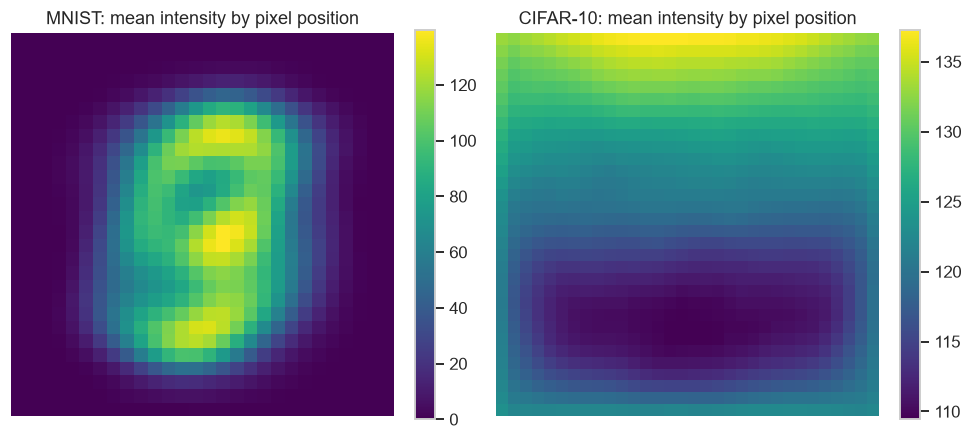

In [11]:
# Mean pixel intensity at each spatial location (where does the content live?)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, d) in zip(axes, DS.items()):
    X = d["Xtr"]
    m = X.mean(axis=0, dtype=np.float32).mean(axis=-1)
    im = ax.imshow(m, cmap="viridis"); ax.set_title(f"{name}: mean intensity by pixel position")
    ax.axis("off"); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## 6. Per-image statistics & outliers

* **Brightness** = mean pixel value of an image (0-1)
* **Contrast** = standard deviation of the pixel values of an image

Both are computed in batches to keep memory low.

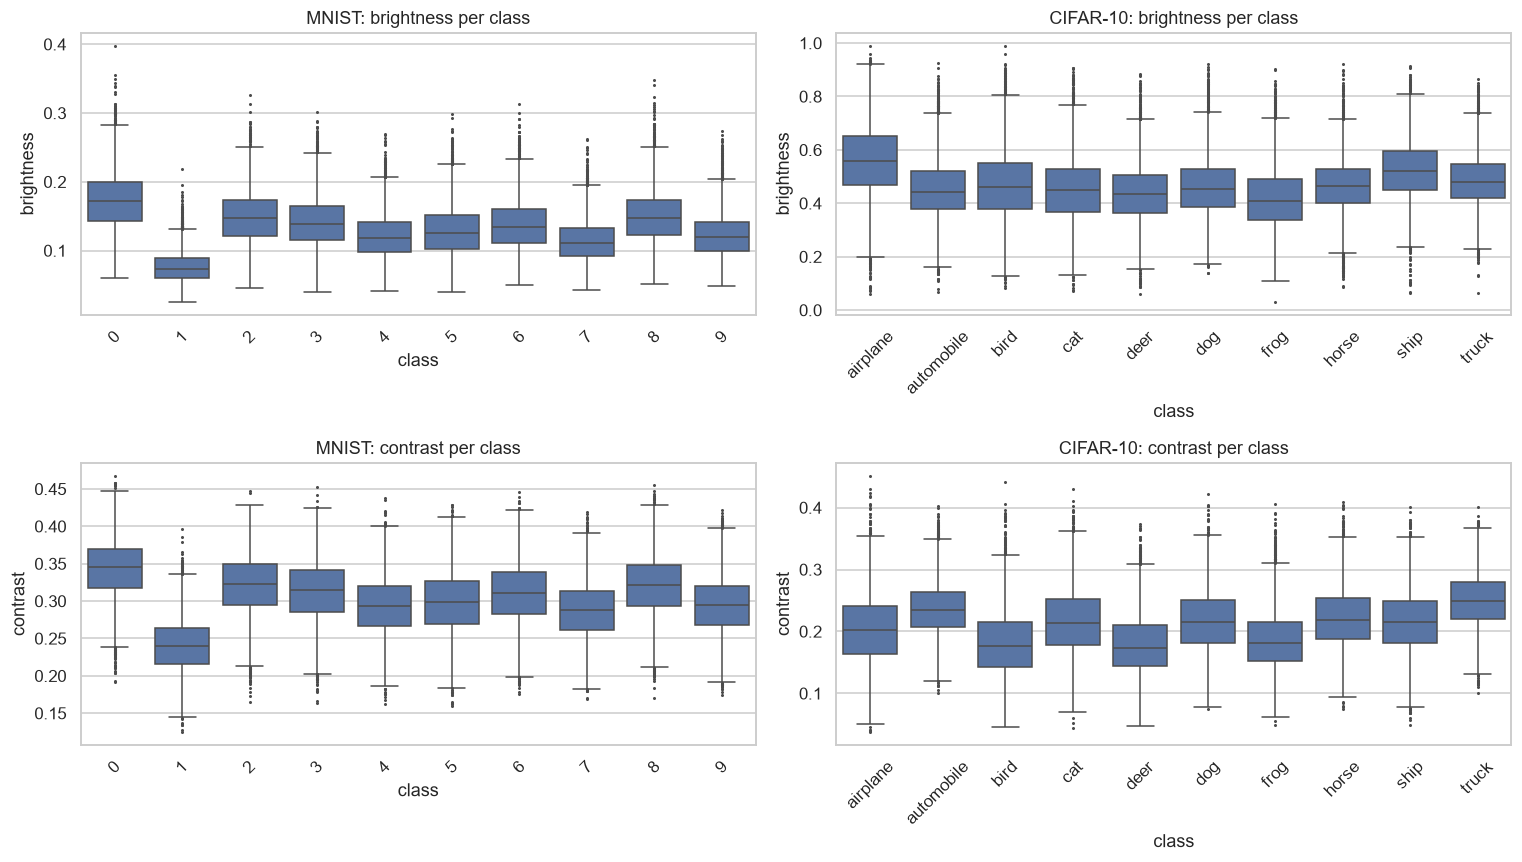

In [12]:
def image_stats(X, bs=5000):
    out = []
    for i in range(0, len(X), bs):
        b = X[i:i + bs].astype(np.float32) / 255.0
        out.append(np.stack([b.mean(axis=(1, 2, 3)), b.std(axis=(1, 2, 3))], axis=1))
    return np.concatenate(out)

for name, d in DS.items():
    d["stats_tr"] = image_stats(d["Xtr"])
    d["stats_te"] = image_stats(d["Xte"])

def stats_frame(name):
    d = DS[name]
    cls = np.array(d["classes"])
    df = pd.DataFrame({"class": cls[d["ytr"]], "brightness": d["stats_tr"][:, 0], "contrast": d["stats_tr"][:, 1]})
    return df

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for j, name in enumerate(DS):
    df = stats_frame(name); order = DS[name]["classes"]
    sns.boxplot(data=df, x="class", y="brightness", order=order, ax=axes[0, j], fliersize=1)
    axes[0, j].set_title(f"{name}: brightness per class"); axes[0, j].tick_params(axis="x", rotation=45)
    sns.boxplot(data=df, x="class", y="contrast", order=order, ax=axes[1, j], fliersize=1)
    axes[1, j].set_title(f"{name}: contrast per class"); axes[1, j].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

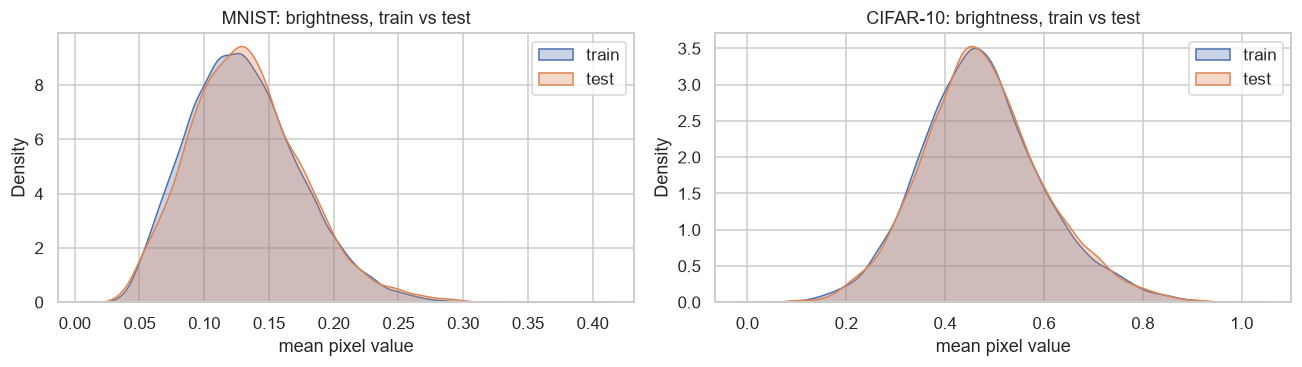

In [13]:
# Train vs test distribution of brightness (a quick covariate-shift check)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, (name, d) in zip(axes, DS.items()):
    sns.kdeplot(d["stats_tr"][:, 0], ax=ax, label="train", fill=True, alpha=0.3)
    sns.kdeplot(d["stats_te"][:, 0], ax=ax, label="test", fill=True, alpha=0.3)
    ax.set_title(f"{name}: brightness, train vs test"); ax.set_xlabel("mean pixel value"); ax.legend()
plt.tight_layout(); plt.show()

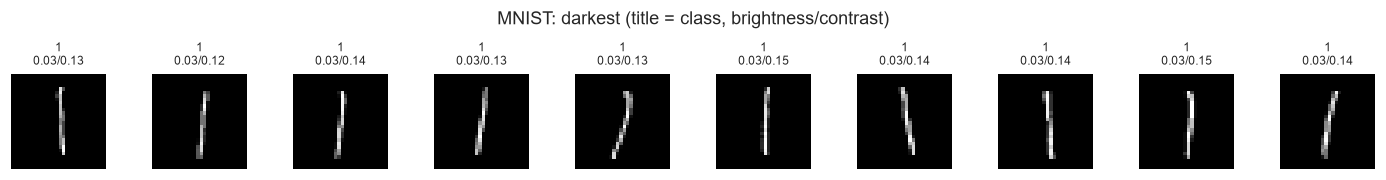

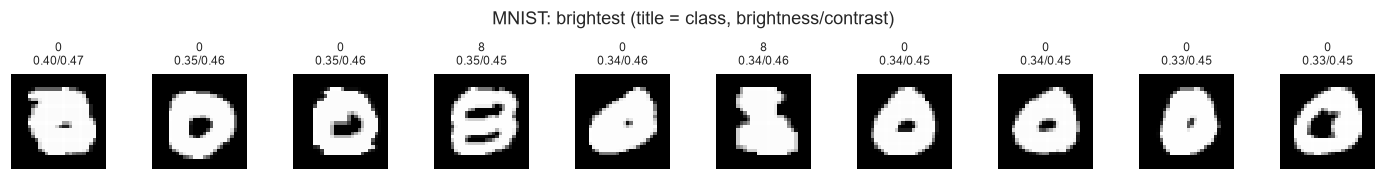

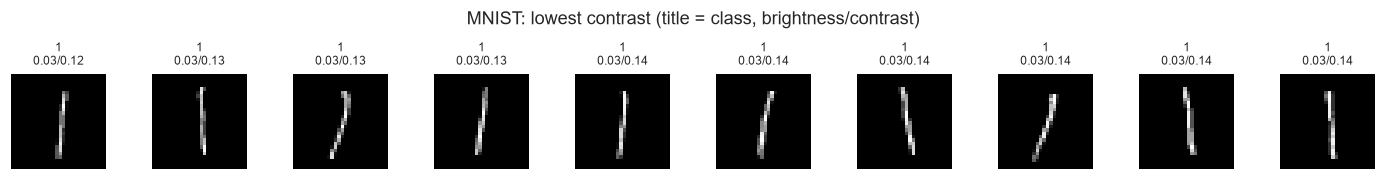

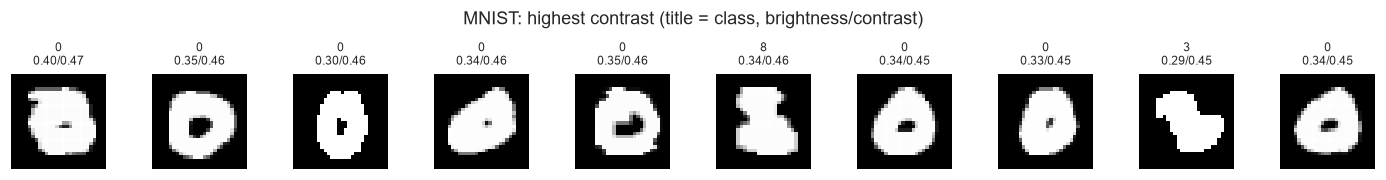

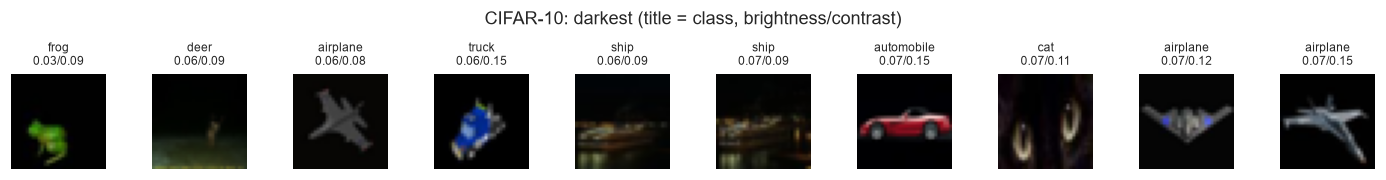

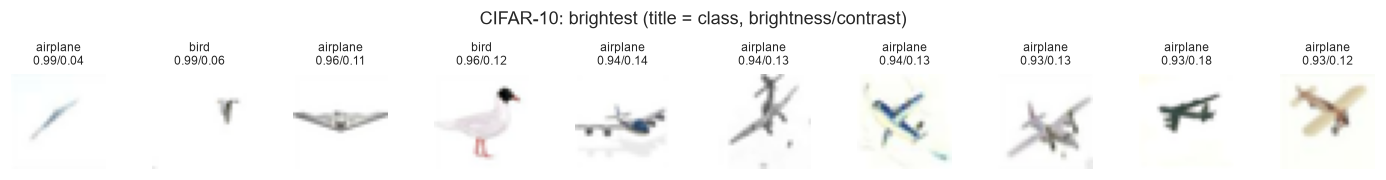

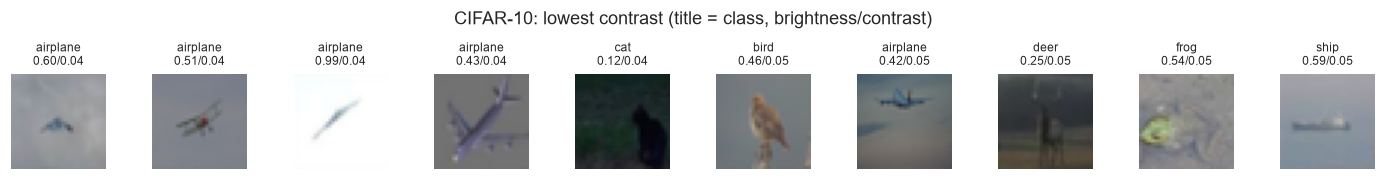

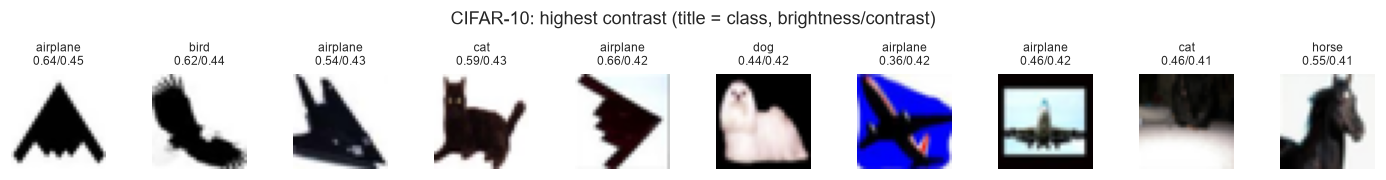

In [14]:
# Extreme images: darkest, brightest, lowest and highest contrast
for name, d in DS.items():
    st = d["stats_tr"]; X = d["Xtr"]; y = d["ytr"]; cls = d["classes"]
    for label, order in [("darkest", np.argsort(st[:, 0])), ("brightest", np.argsort(-st[:, 0])),
                         ("lowest contrast", np.argsort(st[:, 1])), ("highest contrast", np.argsort(-st[:, 1]))]:
        idx = order[:10]
        show_images(X[idx], [f"{cls[y[i]]}\n{st[i,0]:.2f}/{st[i,1]:.2f}" for i in idx],
                    suptitle=f"{name}: {label} (title = class, brightness/contrast)")

## 7. Class-average and class-variability images

The **mean image** shows the canonical layout of each class, the **std image** shows where the class varies most.

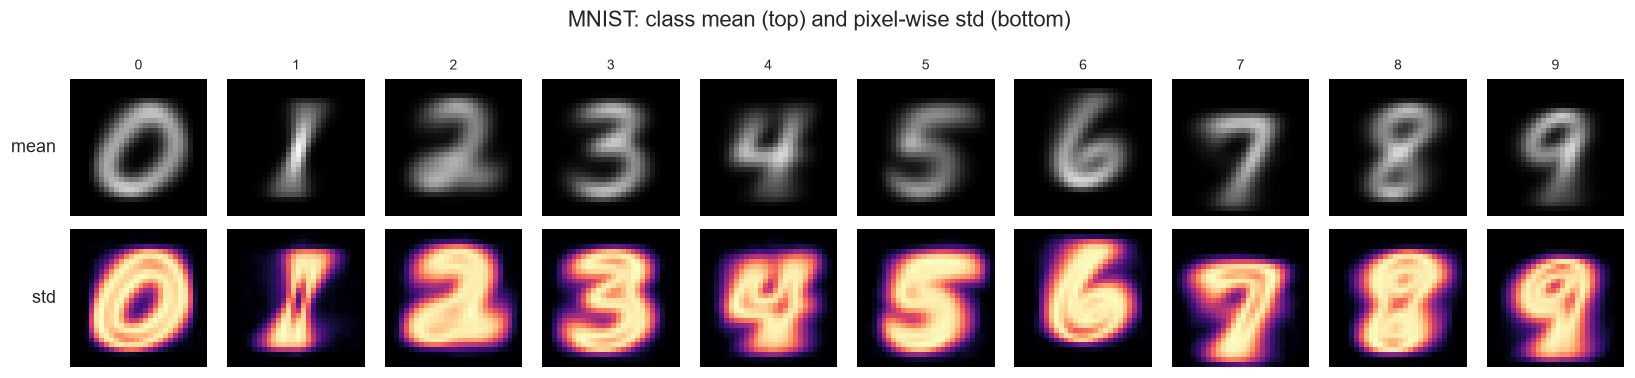

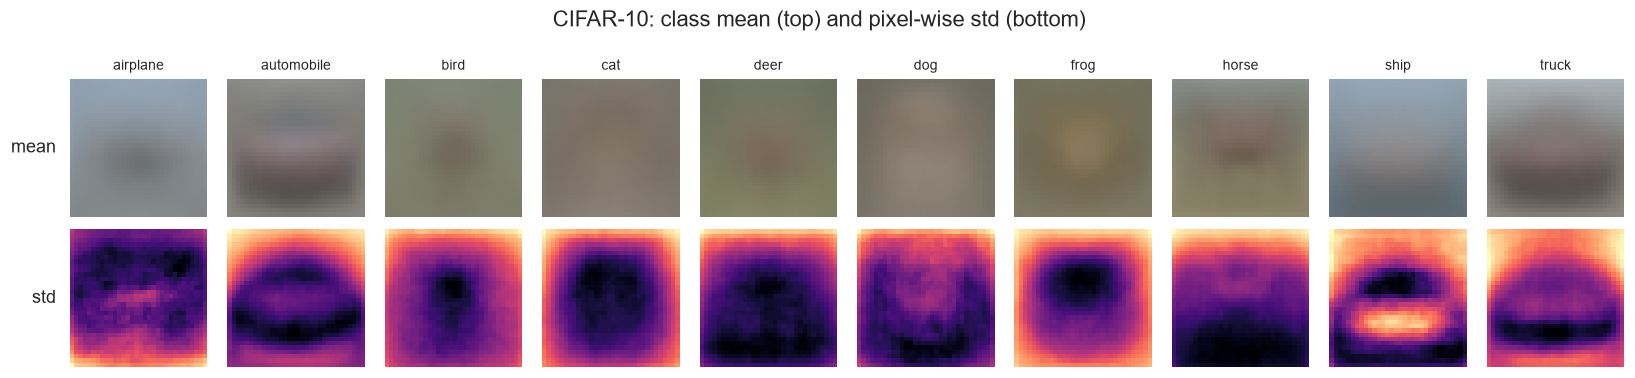

In [15]:
for name, d in DS.items():
    X, y, cls = d["Xtr"], d["ytr"], d["classes"]
    means = np.stack([X[y == c].mean(axis=0, dtype=np.float32) for c in range(10)])
    stds = np.stack([X[y == c].std(axis=0, dtype=np.float32) for c in range(10)])
    d["class_means"] = means
    fig, axes = plt.subplots(2, 10, figsize=(15, 3.6))
    for c in range(10):
        axes[0, c].imshow(means[c].squeeze() / 255.0, cmap=cmap_for(X), vmin=0, vmax=1)
        axes[0, c].set_title(cls[c], fontsize=9)
        im = axes[1, c].imshow(stds[c].mean(axis=-1) if X.shape[-1] > 1 else stds[c].squeeze(), cmap="magma")
        axes[0, c].axis("off"); axes[1, c].axis("off")
    axes[0, 0].text(-0.1, 0.5, "mean", transform=axes[0, 0].transAxes, ha="right", va="center")
    axes[1, 0].text(-0.1, 0.5, "std", transform=axes[1, 0].transAxes, ha="right", va="center")
    fig.suptitle(f"{name}: class mean (top) and pixel-wise std (bottom)")
    plt.tight_layout(); plt.show()

## 8. Inter-class similarity

Euclidean distance between class-mean images. Small distances hint at classes that will be confused in a simple model (e.g. 4/9 and 3/5/8 for MNIST, cat/dog or automobile/truck for CIFAR-10).

MNIST - closest class pairs: [('4', '9', 2.48), ('7', '9', 2.99), ('5', '8', 3.1), ('3', '5', 3.12), ('3', '8', 3.63)]
CIFAR-10 - closest class pairs: [('cat', 'dog', 1.59), ('bird', 'horse', 1.63), ('cat', 'deer', 1.83), ('deer', 'frog', 1.86), ('bird', 'cat', 2.04)]


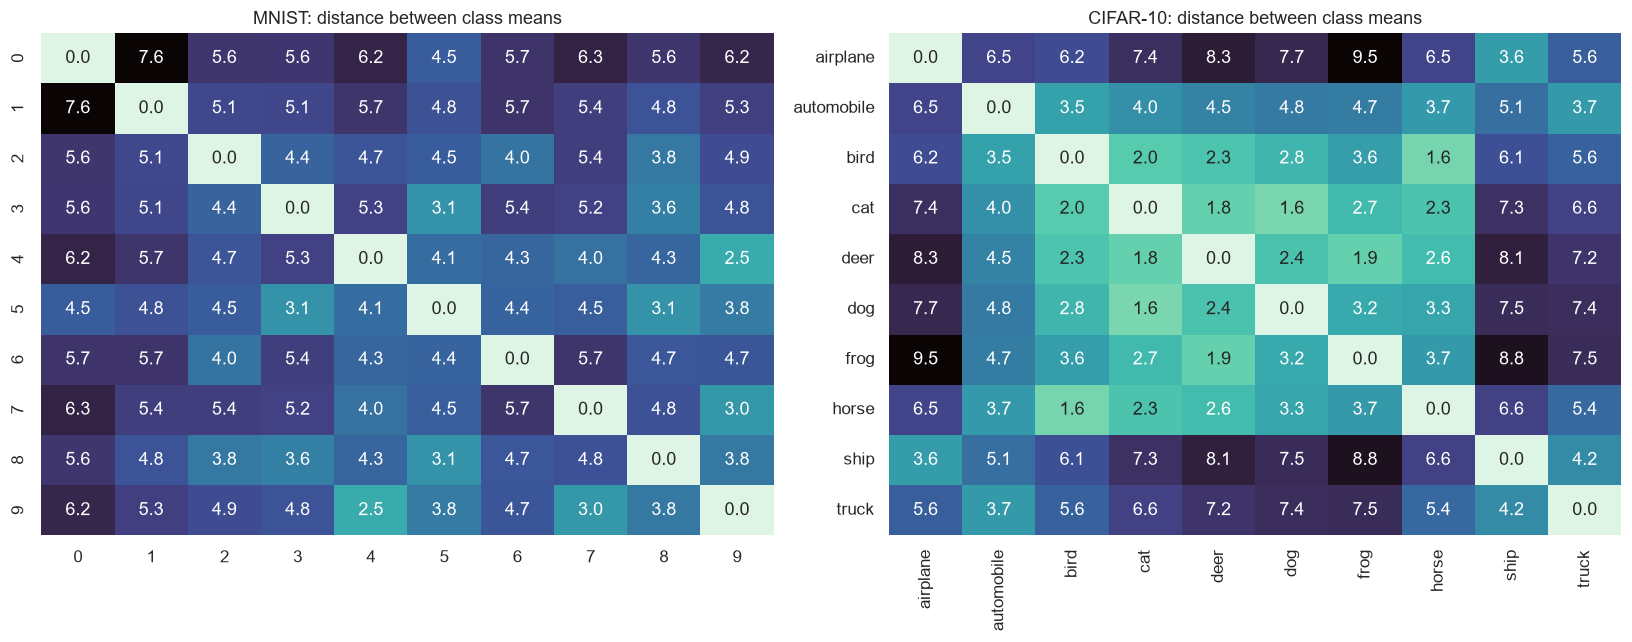

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, d) in zip(axes, DS.items()):
    M = d["class_means"].reshape(10, -1) / 255.0
    D = np.linalg.norm(M[:, None, :] - M[None, :, :], axis=-1)
    sns.heatmap(D, annot=True, fmt=".1f", cmap="mako_r", xticklabels=d["classes"], yticklabels=d["classes"], ax=ax, cbar=False)
    ax.set_title(f"{name}: distance between class means")
    iu = np.triu_indices(10, 1)
    order = np.argsort(D[iu])[:5]
    print(name, "- closest class pairs:",
          [(d["classes"][iu[0][k]], d["classes"][iu[1][k]], round(float(D[iu][k]), 2)) for k in order])
plt.tight_layout(); plt.show()

## 9. Duplicates & train/test leakage

Exact duplicates are detected with an MD5 hash of the raw pixel bytes. Overlap between train and test would inflate test performance.

In [17]:
def hashes(X):
    return [hashlib.md5(x.tobytes()).hexdigest() for x in X]

dup_rows = []
for name, d in DS.items():
    htr, hte = hashes(d["Xtr"]), hashes(d["Xte"])
    d["htr"], d["hte"] = htr, hte
    set_tr, set_te = set(htr), set(hte)
    dup_rows.append({"dataset": name,
                     "exact duplicates inside train": len(htr) - len(set_tr),
                     "exact duplicates inside test": len(hte) - len(set_te),
                     "test images also in train": sum(h in set_tr for h in hte)})
pd.DataFrame(dup_rows).set_index("dataset")

,exact duplicates inside train,exact duplicates inside test,test images also in train
dataset,,,
MNIST,0,0,0
CIFAR-10,0,0,0


In [18]:
# Do duplicated images carry conflicting labels?
for name, d in DS.items():
    df = pd.DataFrame({"h": d["htr"], "y": d["ytr"]})
    g = df.groupby("h")["y"].nunique()
    conflicts = int((g > 1).sum())
    print(f"{name}: duplicate-hash groups with conflicting labels = {conflicts}")

MNIST: duplicate-hash groups with conflicting labels = 0
CIFAR-10: duplicate-hash groups with conflicting labels = 0


## 10. Dimensionality reduction

### 10.1 PCA
How many components are needed to retain 90 / 95 / 99 % of the variance tells us how redundant the raw pixel space is.

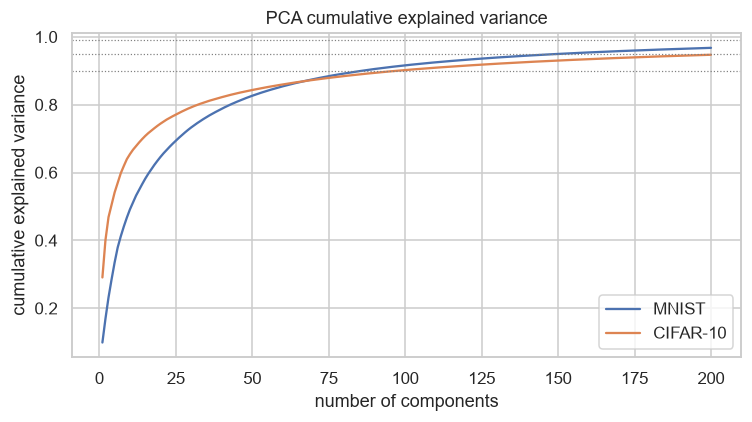

,raw dims,PCs for 90%,PCs for 95%,PCs for 99%,variance in PC1+PC2
dataset,,,,,
MNIST,784,86,151,>200,0.169
CIFAR-10,3072,98,201,>200,0.401


In [19]:
pca_models, pca_samples = {}, {}
fig, ax = plt.subplots(figsize=(7, 4))
pca_rows = []
for name, d in DS.items():
    idx = sample_idx(len(d["Xtr"]), 10000)
    Xs, ys = flatten_float(d["Xtr"][idx]), d["ytr"][idx]
    pca = PCA(n_components=min(200, Xs.shape[1]), random_state=SEED).fit(Xs)
    cum = np.cumsum(pca.explained_variance_ratio_)
    ax.plot(np.arange(1, len(cum) + 1), cum, label=name)
    pca_models[name], pca_samples[name] = pca, (Xs, ys)
    pca_rows.append({"dataset": name, "raw dims": Xs.shape[1],
                     "PCs for 90%": int(np.searchsorted(cum, 0.90) + 1),
                     "PCs for 95%": int(np.searchsorted(cum, 0.95) + 1),
                     "PCs for 99%": int(np.searchsorted(cum, 0.99) + 1) if cum[-1] >= 0.99 else f">{len(cum)}",
                     "variance in PC1+PC2": round(float(cum[1]), 3)})
for q in (0.9, 0.95, 0.99): ax.axhline(q, color="gray", ls=":", lw=0.8)
ax.set_xlabel("number of components"); ax.set_ylabel("cumulative explained variance"); ax.set_title("PCA cumulative explained variance"); ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(pca_rows).set_index("dataset")

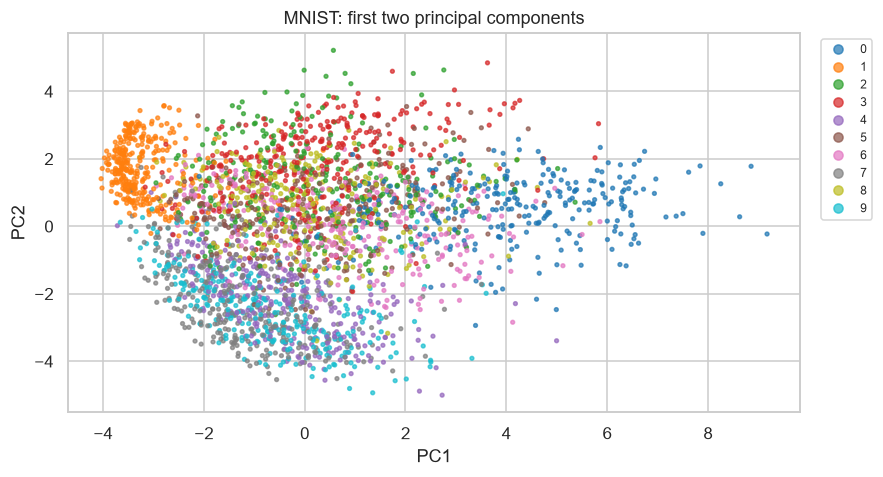

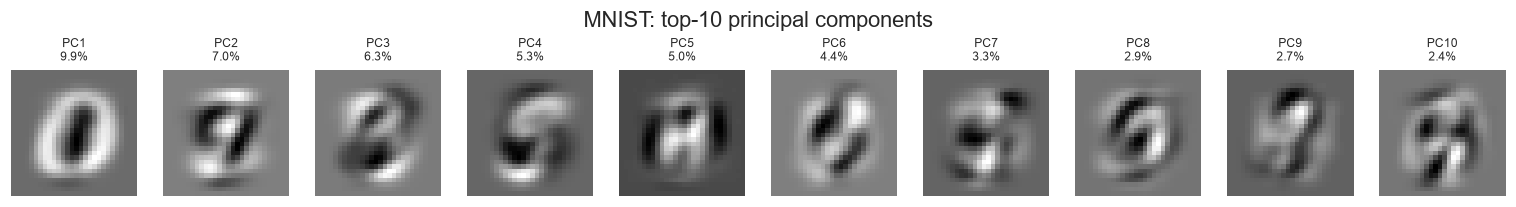

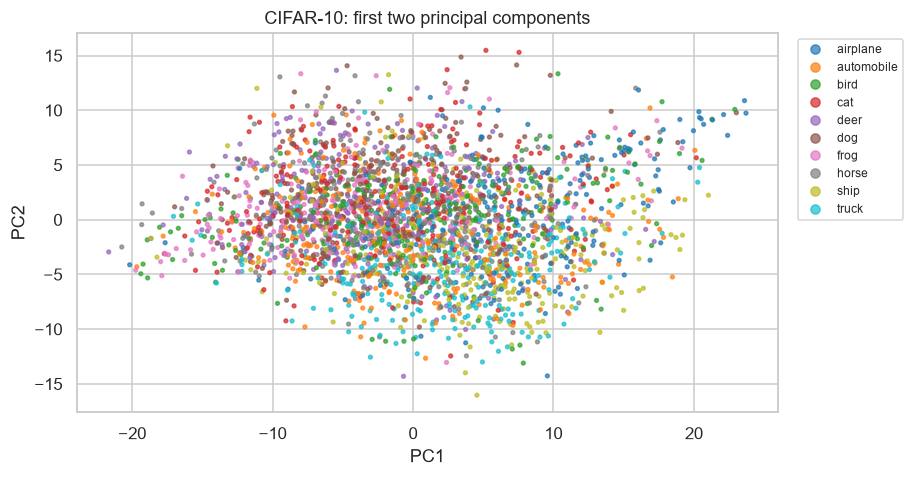

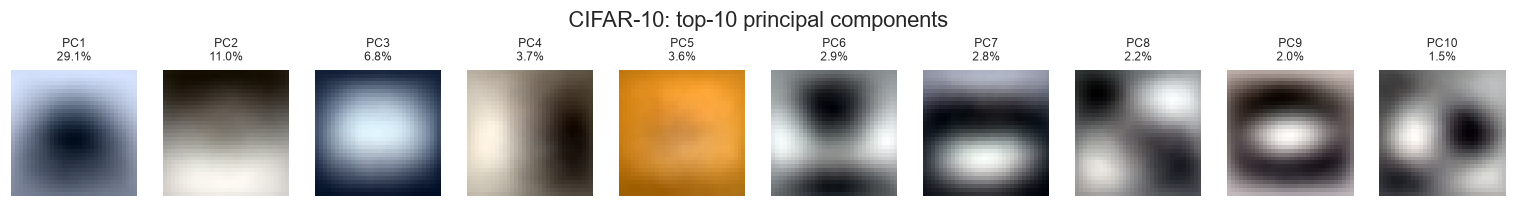

In [20]:
# 2-D PCA projection and the first principal components ("eigen-images")
for name, d in DS.items():
    pca = pca_models[name]; Xs, ys = pca_samples[name]
    Z = pca.transform(Xs)[:3000]; yz = ys[:3000]
    fig = plt.figure(figsize=(15, 4.5))
    ax = fig.add_subplot(1, 2, 1)
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=yz, cmap="tab10", s=6, alpha=0.7)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(f"{name}: first two principal components")
    handles, _ = sc.legend_elements()
    ax.legend(handles, d["classes"], bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    shape = d["Xtr"].shape[1:]
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 10, figsize=(14, 1.9))
    for k in range(10):
        comp = pca.components_[k].reshape(shape)
        comp = (comp - comp.min()) / (comp.max() - comp.min() + 1e-9)
        axes[k].imshow(comp.squeeze(), cmap=cmap_for(d["Xtr"])); axes[k].axis("off")
        axes[k].set_title(f"PC{k+1}\n{pca.explained_variance_ratio_[k]*100:.1f}%", fontsize=8)
    fig.suptitle(f"{name}: top-10 principal components"); plt.tight_layout(); plt.show()

### 10.2 t-SNE

Non-linear 2-D embedding of a 3,000-image subsample (first reduced to 50 PCA dimensions for speed). Takes roughly a minute per dataset.

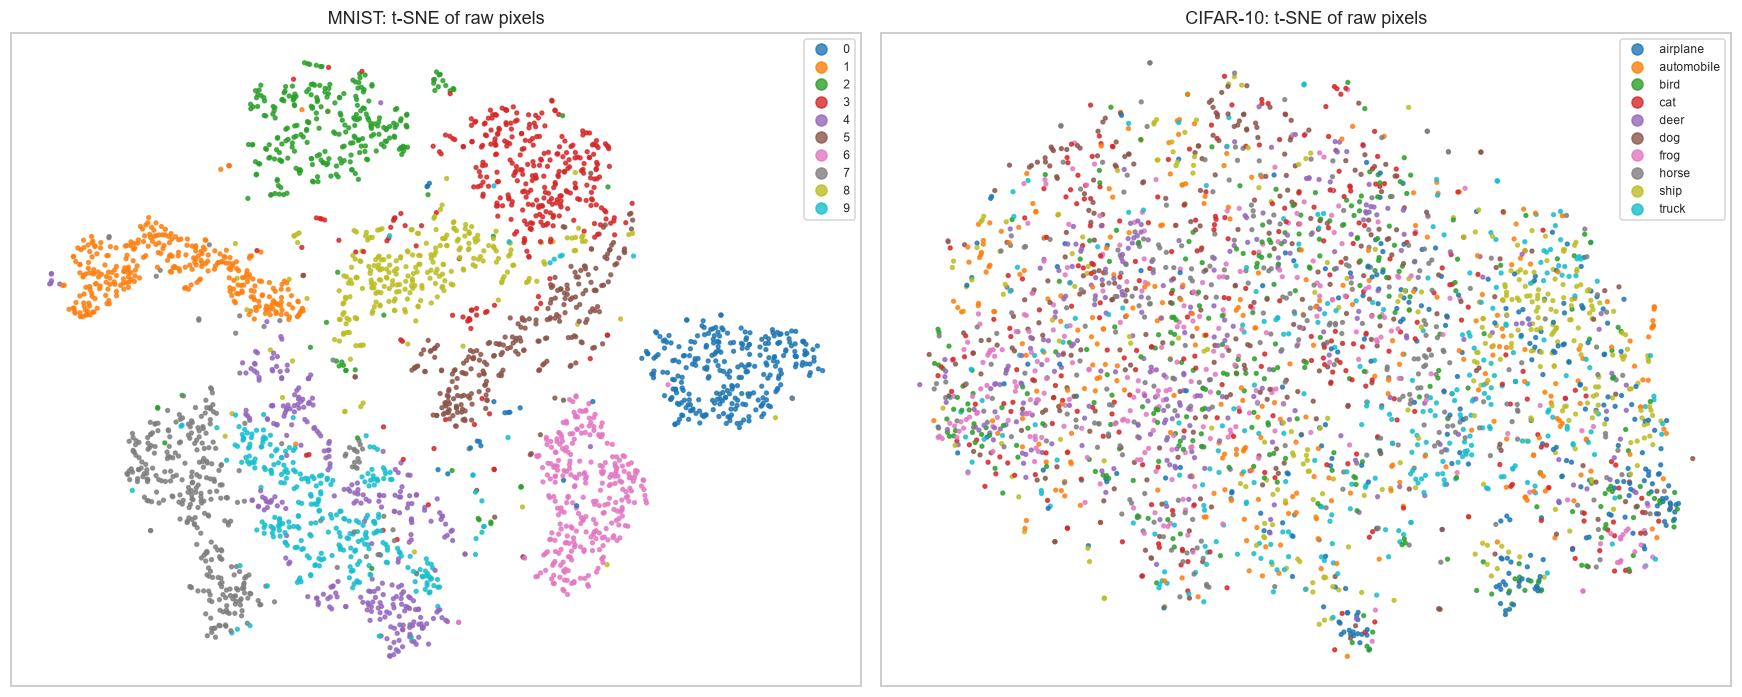

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (name, d) in zip(axes, DS.items()):
    Xs, ys = pca_samples[name]
    n = min(3000, len(Xs))
    Z50 = PCA(n_components=50, random_state=SEED).fit_transform(Xs[:n])
    emb = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Z50)
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=ys[:n], cmap="tab10", s=6, alpha=0.8)
    ax.set_title(f"{name}: t-SNE of raw pixels"); ax.set_xticks([]); ax.set_yticks([])
    handles, _ = sc.legend_elements(); ax.legend(handles, d["classes"], fontsize=8, markerscale=1.2, loc="best")
plt.tight_layout(); plt.show()

## 11. Dataset-specific analysis

### 11.1 MNIST: ink, bounding box and centre of mass

MNIST digits were size-normalised into a 20x20 box and centred by centre of mass within the 28x28 frame. We verify that and look at how much "ink" each digit uses.

ink fraction        bbox height        bbox width        aspect (h/w)  \
              mean    std        mean    std       mean    std         mean   
class                                                                         
0            0.198  0.043      19.422  1.342     17.595  2.558        1.137   
1            0.088  0.023      19.991  0.158      8.632  3.900        2.859   
2            0.171  0.040      19.104  1.807     17.852  2.537        1.103   
3            0.164  0.040      19.817  0.735     15.865  2.950        1.302   
4            0.141  0.033      19.815  0.722     15.764  2.975        1.311   
5            0.151  0.040      18.797  2.085     17.551  2.876        1.118   
6            0.158  0.039      19.913  0.541     14.573  2.945        1.429   
7            0.132  0.032      19.815  0.813     15.400  2.937        1.342   
8            0.174  0.040      19.849  0.695     15.194  3.031        1.367   
9            0.143  0.034      19.967  0.326     13.620  2.724        1.529   

               com_x          com_y         
         std    mean    std    mean    std  
class                                       
0      0.235  14.014  0.292  14.001  0.291  
1      1.381  14.021  0.304  13.963  0.292  
2      0.248  13.999  0.287  14.006  0.290  
3      0.296  14.009  0.289  13.995  0.290  
4      0.295  14.004  0.291  14.000  0.290  
5      0.303  14.004  0.288  14.001  0.288  
6      0.322  14.001  0.288  14.000  0.283  
7      0.298  14.007  0.291  14.005  0.289  
8      0.317  14.008  0.289  14.000  0.288  
9      0.324  14.000  0.287  13.994  0.288

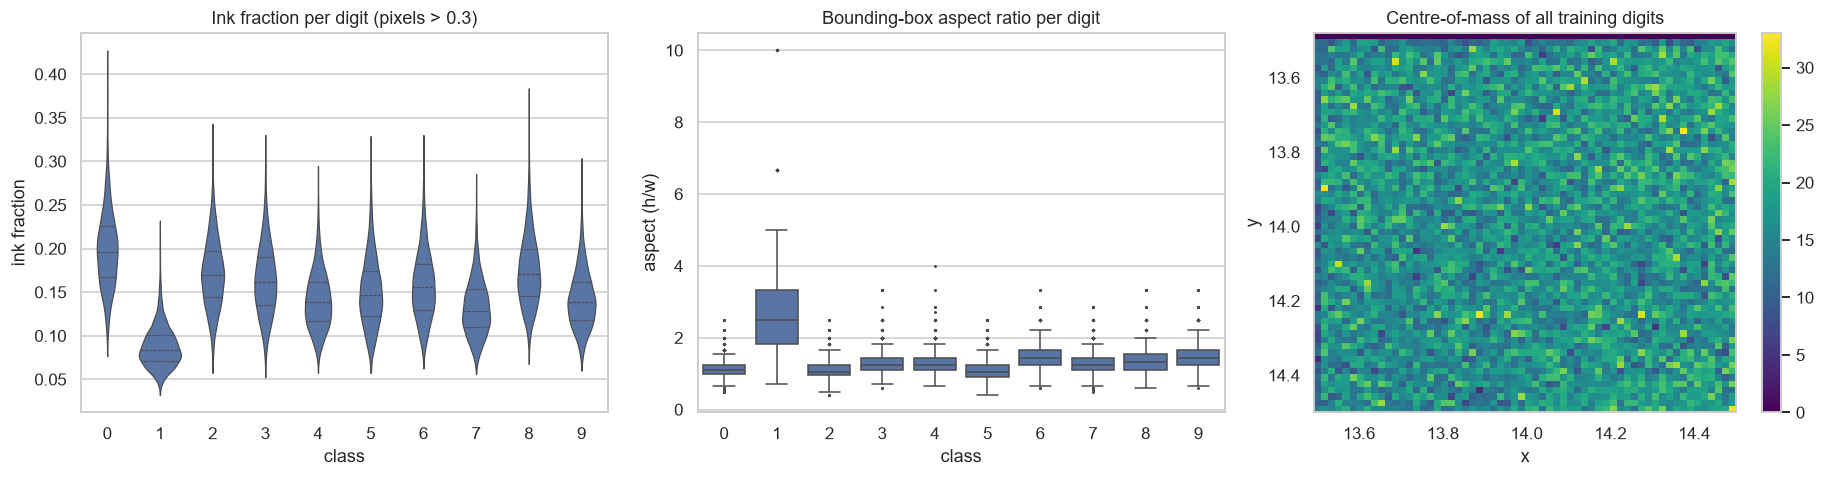

In [22]:
d = DS["MNIST"]
X = d["Xtr"][..., 0].astype(np.float32) / 255.0
y, cls = d["ytr"], d["classes"]
N, H, W = X.shape

mask = X > 0.3
ink = mask.mean(axis=(1, 2))                       # fraction of "on" pixels
rows_any, cols_any = mask.any(axis=2), mask.any(axis=1)
first_r, last_r = rows_any.argmax(1), H - 1 - rows_any[:, ::-1].argmax(1)
first_c, last_c = cols_any.argmax(1), W - 1 - cols_any[:, ::-1].argmax(1)
bbox_h, bbox_w = last_r - first_r + 1, last_c - first_c + 1

tot = X.sum(axis=(1, 2)) + 1e-9
com_y = (X.sum(axis=2) * np.arange(H)).sum(1) / tot
com_x = (X.sum(axis=1) * np.arange(W)).sum(1) / tot

mn = pd.DataFrame({"class": np.array(cls)[y], "ink fraction": ink, "bbox height": bbox_h, "bbox width": bbox_w,
                   "aspect (h/w)": bbox_h / bbox_w, "com_x": com_x, "com_y": com_y})
display(mn.groupby("class").agg(["mean", "std"]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.violinplot(data=mn, x="class", y="ink fraction", order=cls, ax=axes[0], cut=0, inner="quartile", linewidth=0.8)
axes[0].set_title("Ink fraction per digit (pixels > 0.3)")
sns.boxplot(data=mn, x="class", y="aspect (h/w)", order=cls, ax=axes[1], fliersize=1)
axes[1].set_title("Bounding-box aspect ratio per digit")
h = axes[2].hist2d(mn["com_x"], mn["com_y"], bins=60, cmap="viridis")
axes[2].set_title("Centre-of-mass of all training digits"); axes[2].set_xlabel("x"); axes[2].set_ylabel("y")
axes[2].invert_yaxis(); plt.colorbar(h[3], ax=axes[2])
plt.tight_layout(); plt.show()

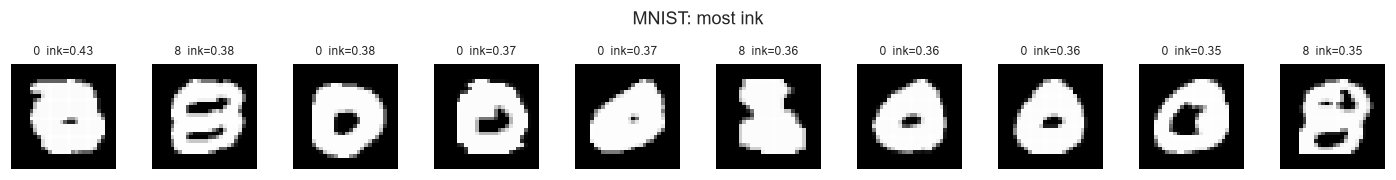

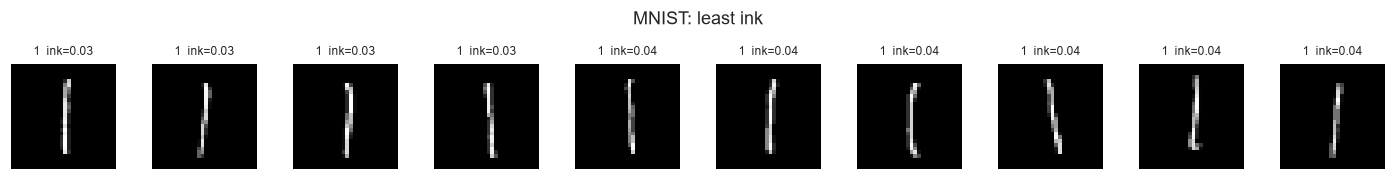

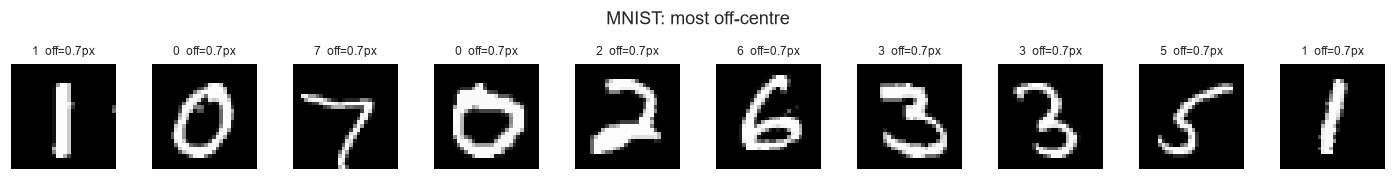

In [23]:
# Typical outliers: most/least ink and most off-centre digits
idx_ink_hi, idx_ink_lo = np.argsort(-ink)[:10], np.argsort(ink)[:10]
off = np.hypot(com_x - com_x.mean(), com_y - com_y.mean()); idx_off = np.argsort(-off)[:10]
Xd = d["Xtr"]
show_images(Xd[idx_ink_hi], [f"{cls[y[i]]}  ink={ink[i]:.2f}" for i in idx_ink_hi], suptitle="MNIST: most ink")
show_images(Xd[idx_ink_lo], [f"{cls[y[i]]}  ink={ink[i]:.2f}" for i in idx_ink_lo], suptitle="MNIST: least ink")
show_images(Xd[idx_off], [f"{cls[y[i]]}  off={off[i]:.1f}px" for i in idx_off], suptitle="MNIST: most off-centre")

### 11.2 CIFAR-10: colour & texture

Colour is a strong cue for several classes (blue sky for airplane/ship, green/brown for deer/frog/horse). Edge density (mean Sobel magnitude on the grey-scale image) is a simple texture/complexity proxy.

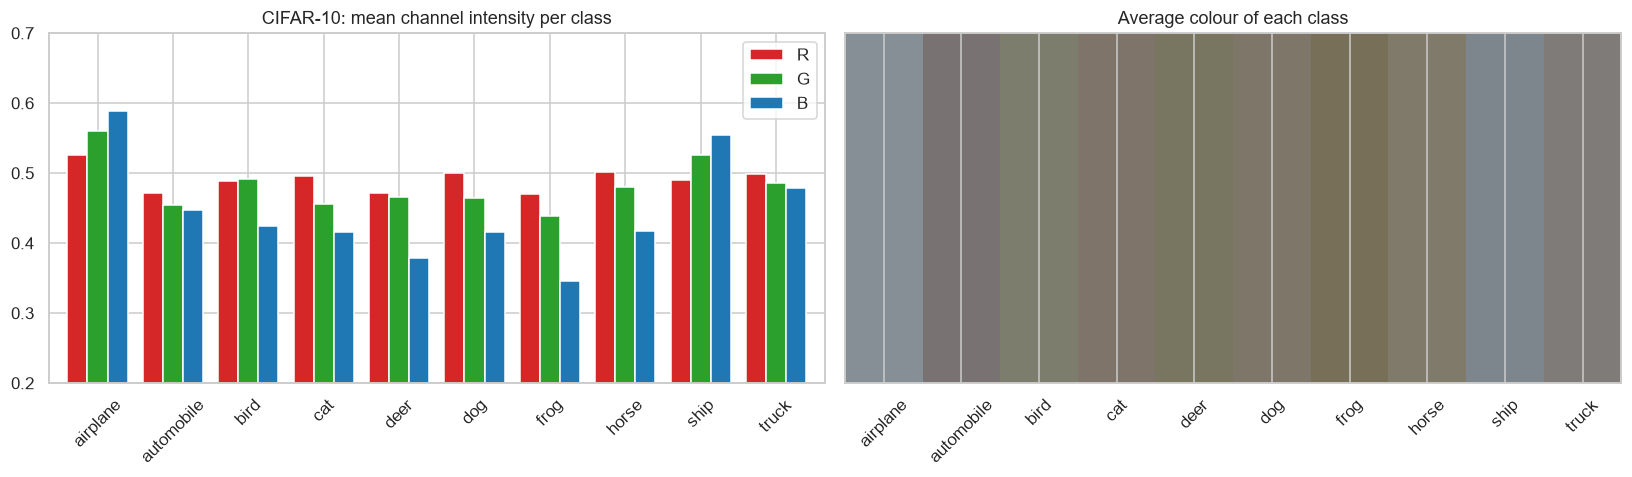

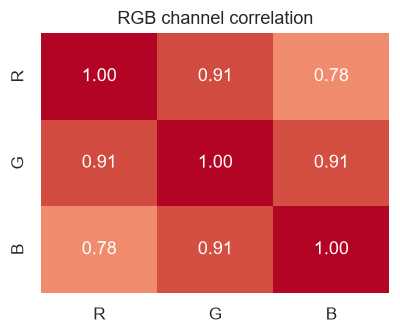

In [24]:
d = DS["CIFAR-10"]
X, y, cls = d["Xtr"], d["ytr"], d["classes"]

# Mean RGB per class
rgb = np.stack([X[y == c].mean(axis=(0, 1, 2), dtype=np.float64) for c in range(10)]) / 255.0
rgb_df = pd.DataFrame(rgb, index=cls, columns=["R", "G", "B"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
rgb_df.plot.bar(ax=axes[0], color=["tab:red", "tab:green", "tab:blue"], width=0.8)
axes[0].set_title("CIFAR-10: mean channel intensity per class"); axes[0].set_ylim(0.2, 0.7); axes[0].tick_params(axis="x", rotation=45)
swatch = rgb[None, :, :]                       # 1 x 10 x 3 strip of "average colour"
axes[1].imshow(np.repeat(swatch, 3, axis=0), aspect="auto"); axes[1].set_xticks(range(10)); axes[1].set_xticklabels(cls, rotation=45)
axes[1].set_yticks([]); axes[1].set_title("Average colour of each class")
plt.tight_layout(); plt.show()

# Channel correlation (pixel level, subsample)
sub = X[sample_idx(len(X), 5000)].reshape(-1, 3).astype(np.float32)
sub = sub[RNG.choice(len(sub), 200000, replace=False)] if len(sub) > 200000 else sub
fig, ax = plt.subplots(figsize=(3.8, 3.2))
sns.heatmap(np.corrcoef(sub.T), annot=True, fmt=".2f", xticklabels="RGB", yticklabels="RGB", cmap="coolwarm", vmin=0, vmax=1, ax=ax, cbar=False)
ax.set_title("RGB channel correlation"); plt.tight_layout(); plt.show()

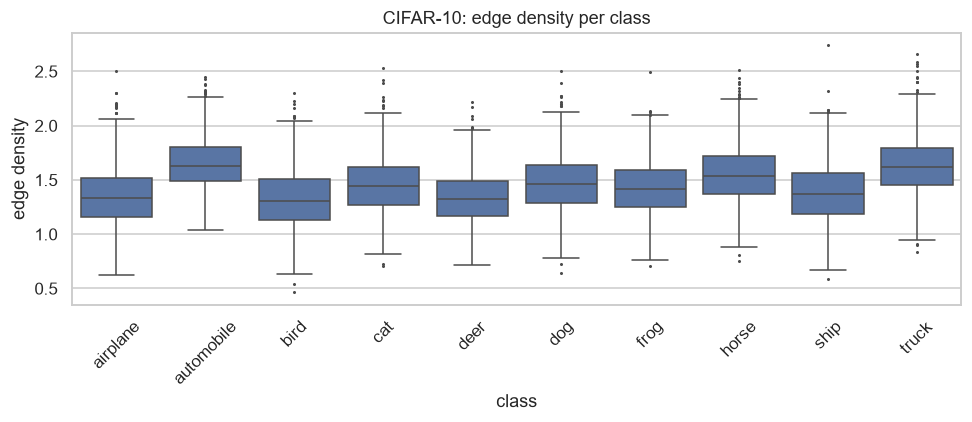

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
airplane,1001.0,1.356,0.285,0.622,1.159,1.331,1.521,2.503
automobile,1003.0,1.644,0.241,1.042,1.487,1.631,1.802,2.447
bird,1016.0,1.323,0.277,0.464,1.128,1.304,1.504,2.301
cat,1031.0,1.452,0.263,0.703,1.270,1.444,1.619,2.528
deer,941.0,1.330,0.244,0.717,1.168,1.321,1.486,2.220
dog,1025.0,1.463,0.266,0.639,1.284,1.459,1.640,2.508
frog,977.0,1.424,0.251,0.710,1.253,1.417,1.591,2.495
horse,1011.0,1.549,0.266,0.752,1.372,1.541,1.722,2.512
ship,968.0,1.381,0.273,0.587,1.186,1.370,1.560,2.739


In [25]:
# Edge density by class (grayscale Sobel magnitude) on a 10k subsample
idx = sample_idx(len(X), 10000)
gray = (X[idx].astype(np.float32) @ np.array([0.299, 0.587, 0.114], dtype=np.float32)) / 255.0
gx = ndimage.sobel(gray, axis=2); gy = ndimage.sobel(gray, axis=1)
edge = np.hypot(gx, gy).mean(axis=(1, 2))

edf = pd.DataFrame({"class": np.array(cls)[y[idx]], "edge density": edge})
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=edf, x="class", y="edge density", order=cls, ax=ax, fliersize=1)
ax.set_title("CIFAR-10: edge density per class"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
edf.groupby("class")["edge density"].describe().round(3)

## 12. Baseline separability

How well can very simple classifiers separate the classes using only 50 PCA components of the raw pixels? This gives a feel for task difficulty and for which classes are confusable. (10,000 training / 2,000 test images subsample.)

In [26]:
baseline = {}
rows = []
for name, d in DS.items():
    itr = sample_idx(len(d["Xtr"]), 10000); ite = sample_idx(len(d["Xte"]), 2000)
    Xa, ya = flatten_float(d["Xtr"][itr]), d["ytr"][itr]
    Xb, yb = flatten_float(d["Xte"][ite]), d["yte"][ite]
    pca = PCA(n_components=50, random_state=SEED).fit(Xa)
    Za, Zb = pca.transform(Xa), pca.transform(Xb)
    for mname, model in [("kNN (k=5)", KNeighborsClassifier(n_neighbors=5)),
                         ("Logistic Regression", LogisticRegression(max_iter=500))]:
        model.fit(Za, ya); pred = model.predict(Zb)
        acc = accuracy_score(yb, pred)
        rows.append({"dataset": name, "model": mname, "test accuracy": round(acc, 4)})
        baseline[(name, mname)] = (yb, pred)
pd.DataFrame(rows).pivot(index="model", columns="dataset", values="test accuracy")

dataset,CIFAR-10,MNIST
model,,
Logistic Regression,0.3645,0.919
kNN (k=5),0.3140,0.963


MNIST - most confused (true -> predicted): [('4', '9', 0.04), ('4', '1', 0.03), ('2', '8', 0.02), ('8', '3', 0.02), ('9', '7', 0.02)]
CIFAR-10 - most confused (true -> predicted): [('deer', 'bird', 0.27), ('bird', 'deer', 0.26), ('frog', 'deer', 0.24), ('ship', 'airplane', 0.24), ('frog', 'bird', 0.23)]


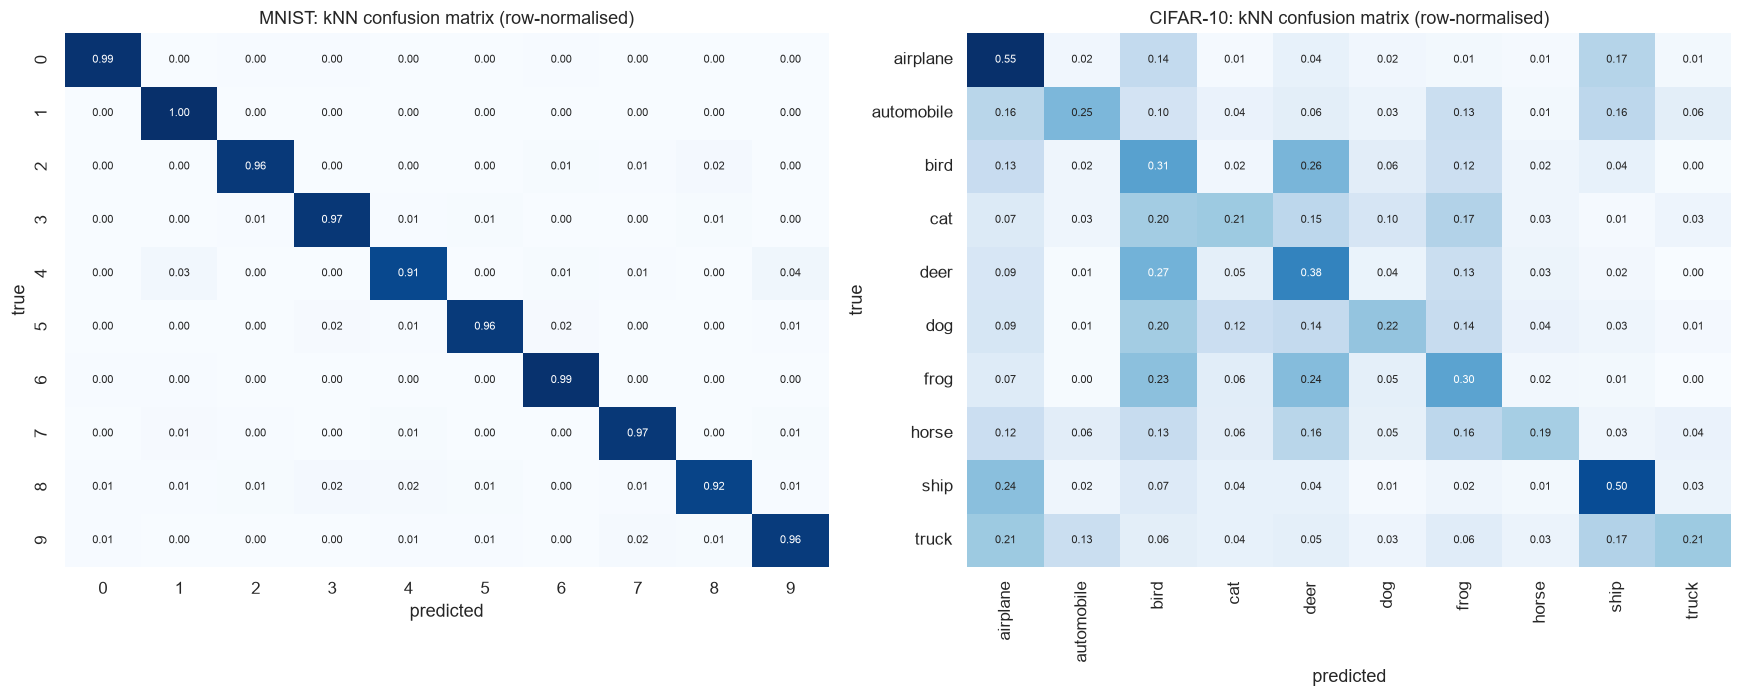

In [27]:
# Confusion matrices (row-normalised) for the kNN baseline + most confused pairs
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (name, d) in zip(axes, DS.items()):
    yb, pred = baseline[(name, "kNN (k=5)")]
    cm = confusion_matrix(yb, pred, labels=range(10)); cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=d["classes"], yticklabels=d["classes"], ax=ax, cbar=False, annot_kws={"size": 7})
    ax.set_title(f"{name}: kNN confusion matrix (row-normalised)"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    off = cmn.copy(); np.fill_diagonal(off, 0)
    top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
    print(name, "- most confused (true -> predicted):",
          [(d["classes"][i], d["classes"][j], round(float(off[i, j]), 2)) for i, j in top])
plt.tight_layout(); plt.show()

## 13. Summary

In [28]:
summary = []
for name, d in DS.items():
    tr_counts = np.bincount(d["ytr"])
    pca = pca_models[name]; cum = np.cumsum(pca.explained_variance_ratio_)
    summary.append({
        "dataset": name,
        "train/test": f"{len(d['Xtr']):,} / {len(d['Xte']):,}",
        "image shape": d["Xtr"].shape[1:],
        "imbalance ratio": round(tr_counts.max() / tr_counts.min(), 2),
        "mean brightness": round(float(d["stats_tr"][:, 0].mean()), 3),
        "mean contrast": round(float(d["stats_tr"][:, 1].mean()), 3),
        "PCs for 95% var.": int(np.searchsorted(cum, 0.95) + 1),
        "train duplicates": len(d["htr"]) - len(set(d["htr"])),
        "test-in-train": sum(h in set(d["htr"]) for h in d["hte"]),
        "kNN acc. (PCA-50)": round(accuracy_score(*baseline[(name, "kNN (k=5)")]), 3),
    })
pd.DataFrame(summary).set_index("dataset").T

dataset,MNIST,CIFAR-10
train/test,"60,000 / 10,000","50,000 / 10,000"
image shape,"(28, 28, 1)","(32, 32, 3)"
imbalance ratio,1.24,1.0
mean brightness,0.131,0.473
mean contrast,0.301,0.211
PCs for 95% var.,151,201
train duplicates,0,0
test-in-train,0,0
kNN acc. (PCA-50),0.963,0.314


### Findings

**MNIST**
* Nearly balanced classes (digit 1 is most frequent, digit 5 the least); no missing values, clean `uint8` range 0-255.
* Sparse and bimodal: most pixels are exactly 0, with a spike near 255. Mean pixel is about 0.13, std about 0.31.
* Digits are centred by centre of mass, so the spatial mean image is a blob in the middle. Digit **1** uses the least ink and has the most extreme aspect ratio; **0** and **8** use the most.
* Low intrinsic dimensionality: a small fraction of the 784 pixels' worth of PCA components captures 95 % of the variance, and even simple kNN on 50 PCs reaches very high accuracy. Confusions concentrate on 4/9, 3/5/8 and 7/9.

**CIFAR-10**
* Balanced (5,000 images per class in train, 1,000 in test).
* Natural images with broad, unimodal pixel distributions, the three channels are strongly correlated (~0.9). Per-channel mean about (0.49, 0.48, 0.45), std about (0.25, 0.24, 0.26).
* Much higher intrinsic dimensionality than MNIST and almost no class structure visible in PCA / t-SNE of raw pixels, so raw-pixel baselines are weak (~35-40 %). Learned convolutional features are needed.
* Colour and background are informative (airplane/ship: blue; deer/frog/horse: green-brown), but the classes with similar appearance (cat/dog, automobile/truck, deer/horse, bird/airplane) are the most confused.
* Only a handful of (near-)duplicates exist, check Section 9 for exact counts.

**Modelling implications**
* No rebalancing is required for either dataset, accuracy is a valid headline metric, supplemented by a confusion matrix.
* Normalise inputs with the per-channel statistics from Section 5.
* MNIST rarely benefits from heavy augmentation beyond small shifts / rotations, CIFAR-10 benefits strongly from random crops, horizontal flips and colour jitter. Avoid vertical flips on both, and horizontal flips on MNIST (they change the digit).